In [1]:
from eo_flood_ops.fier import *
from pathlib import Path
import pandas as pd
import rasterio
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Stacking flood maps into an xarray dataset
folder = Path(r"P:\archivedprojects\11211461-010--eo-flood-ops\HoiAn\classified_events")
files = sorted(folder.glob("hoian_*.tif"))

if not files:
    raise FileNotFoundError(f"No TIFF files found in {folder}")

floodmaps = []
for file in files:
    timestamp = pd.to_datetime(
        file.stem.replace("hoian_", "", 1),
        format="%Y%m%dT%H%M%S",
    )

    with rasterio.open(file) as src:
        data = src.read(1)
        cols = range(src.width)
        rows = range(src.height)
        x_coords, _ = rasterio.transform.xy(src.transform, 0, cols, offset="center")
        _, y_coords = rasterio.transform.xy(src.transform, rows, 0, offset="center")

        floodmap = xr.DataArray(
            data,
            dims=("y", "x"),
            coords={"y": y_coords, "x": x_coords},
            attrs={"crs": src.crs.to_string() if src.crs else None},
        )

    floodmaps.append(floodmap.expand_dims(time=[timestamp]))

ds = xr.concat(floodmaps, dim="time").sortby("time").to_dataset(
    name="floodmap"
)

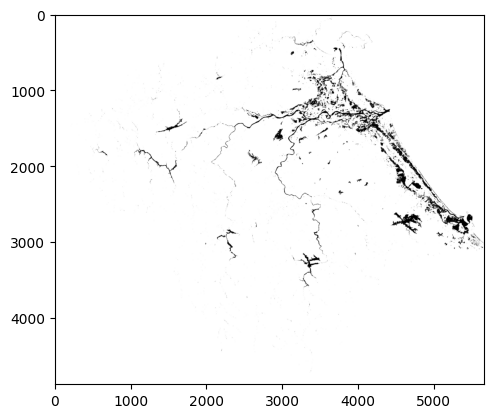

In [3]:
plt.imshow(ds["floodmap"].sel(time="2022-10-15").values[0], cmap="binary");

In [4]:
# Reading water level data from CSV and converting it to an xarray DataArray
waterlevels_fn = R"p:\archivedprojects\11211461-010--eo-flood-ops\HoiAn\water_levels\Water_Level.csv"

df_water = pd.read_csv(waterlevels_fn, skiprows=[1])
df_water.rename(columns={df_water.columns[0]: "datetime"}, inplace=True)
df_water["datetime"] = pd.to_datetime(df_water["datetime"])

# convert timezone from GMT+7 to UTC
df_water["datetime"] = df_water["datetime"] - pd.Timedelta(hours=7)

# set index to datetime
df_water.set_index("datetime", inplace=True)
df_water.replace(-999, np.nan, inplace=True)

da_water = xr.DataArray(
    df_water.to_numpy(),
    coords={
        "time": ("time", df_water.index.to_numpy()),
        "site": ("site", df_water.columns.to_numpy()),
    },
    dims=("time", "site"),
    name="water_level",
)

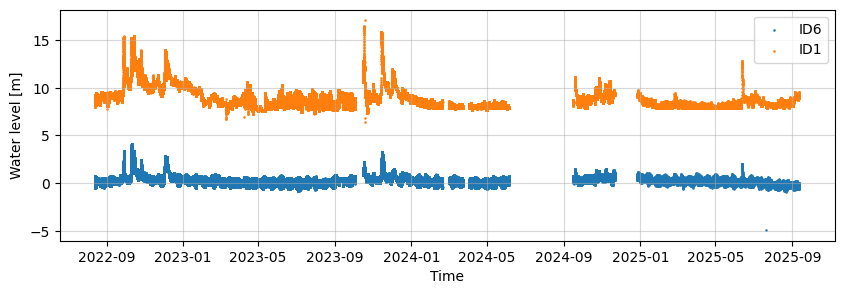

In [5]:
fig, ax = plt.subplots(figsize=(10, 3))

# Plot water level for site ID6 as points
ax.scatter(da_water.sel(site="ID6").time, da_water.sel(site="ID6").values, label="ID6", s=0.7)
ax.scatter(da_water.sel(site="ID6").time, da_water.sel(site="ID1").values, label="ID1", s=0.7)

ax.set_xlabel("Time")
ax.set_ylabel("Water level [m]")
ax.legend()
ax.grid(True, alpha=0.5)

In [6]:
eof_ds = reof(
    da=ds["floodmap"],
    significance_test=True,
    y_dim= "y",
    x_dim= "x",
)

Performing significance test to determine the number of EOF modes...
Number of EOF modes determined by significance test: 3
Performing REOF analysis using the first 3 modes...


In [7]:
hydro_modes = find_hydro_mode(
    ds_eof=eof_ds,
    da_hydro=da_water,
    r_thrd= 0.5,
    p_thrd= 0.2,
    time_dim= "time",
    site_dim= "site",
)

In [8]:
eof_hydro = combine_eof_hydro(
    ds_eof=eof_ds,
    da_hydro=da_water,
    tpc_hydro_r=hydro_modes,
    time_dim="time",
    site_dim="site",
)

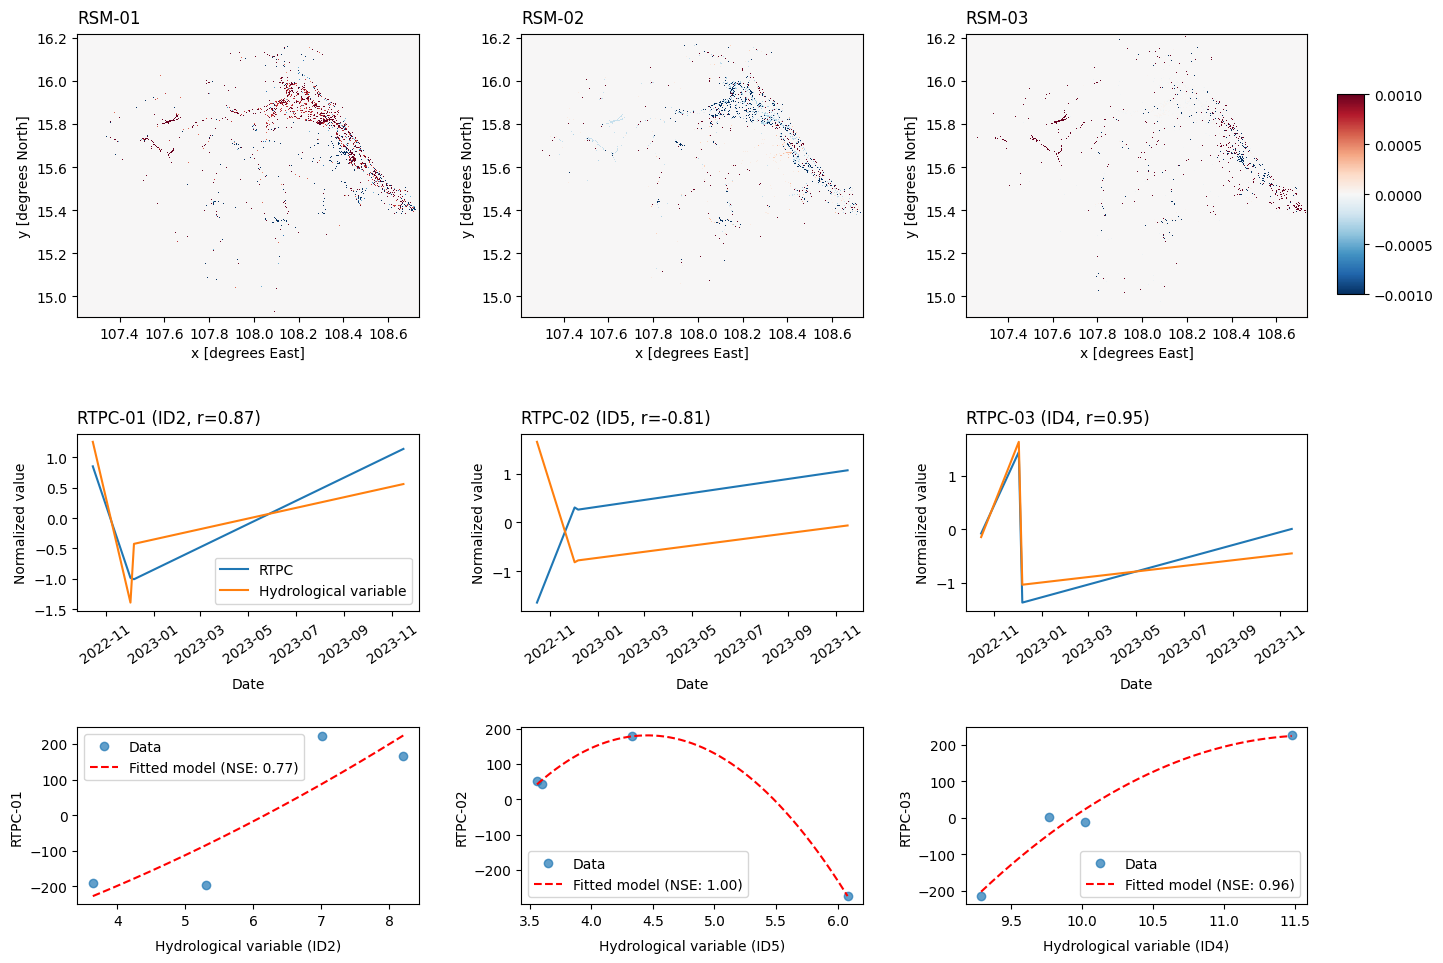

In [9]:
plot_fier_diagnostics(
    eof_hydro,
    spatial_vmin=-0.001,
    spatial_vmax=0.001,
);

In [10]:
eof_hydro

<xarray.Dataset> Size: 443MB
Dimensions:         (mode: 3, y: 4879, x: 5668, time: 4, degree: 3)
Coordinates:
  * mode            (mode) int64 24B 1 2 3
  * y               (y) float64 39kB 16.22 16.22 16.22 16.22 ... 14.9 14.9 14.9
  * x               (x) float64 45kB 107.2 107.2 107.2 ... 108.7 108.7 108.7
  * time            (time) datetime64[ns] 32B 2022-10-15T10:56:00 ... 2023-11...
  * degree          (degree) int64 24B 0 1 2
    site            (mode) object 24B 'ID2' 'ID5' 'ID4'
Data variables:
    spatial_modes   (mode, y, x) float32 332MB 2.748e-14 -1.427e-13 ... 0.0 0.0
    temporal_modes  (mode, time) float32 48B 166.1 -191.8 ... -215.1 0.964
    temporal_mean   (y, x) float32 111MB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    explained_var   (mode) float32 12B 0.421 0.3087 0.2703
    hydro_var       (mode, time) float32 48B 8.21 3.64 5.31 ... 11.48 9.29 9.77
    best_r          (mode) float64 24B 0.8748 -0.808 0.9545
    coefficients    (mode, degree) float32 36B -455.2 46.33 ... 1.817e+03 -78.07

In [33]:
def synthesize(reof_ds: xr.Dataset, q: xr.DataArray, site_dim: str = "site") -> xr.DataArray:
    """Reconstruct an image using the site-matched polynomial for each mode.

    Args:
        reof_ds: Output of combine_eof_hydro(). It must contain ``site``
            indexed by ``mode`` and ``coefficients`` indexed by ``mode`` and
            ``degree``.
        q: Water-level values indexed by ``site_dim``. A single time step is
            expected, for example ``da_water.sel(time=date_str)``.
        site_dim: Name of the site dimension in ``q``.
    """
    if not isinstance(q, xr.DataArray):
        raise TypeError("q must be an xarray.DataArray indexed by site")
    if site_dim not in q.dims:
        raise ValueError(f"q must contain the site dimension {site_dim!r}")
    if "site" not in reof_ds or "coefficients" not in reof_ds:
        raise ValueError("reof_ds must contain 'site' and 'coefficients'")

    modes = reof_ds["mode"].values
    predicted_pcs = []
    used_modes = []

    for mode in modes:
        site = reof_ds["site"].sel(mode=mode).item()
        try:
            q_value = q.sel({site_dim: site}).item()
        except KeyError:
            continue

        if not np.isfinite(q_value):
            continue

        coefficients = reof_ds["coefficients"].sel(mode=mode).values
        pc_value = np.polynomial.polynomial.polyval(q_value, coefficients)
        predicted_pcs.append(pc_value)
        used_modes.append(mode)

    if not used_modes:
        raise ValueError("No mode sites were found in q with finite values")

    pcs = xr.DataArray(
        predicted_pcs,
        dims="mode",
        coords={"mode": used_modes},
    )
    reconstructed = pcs.dot(reof_ds["spatial_modes"].sel(mode=used_modes))
    reconstructed = reconstructed + reof_ds["temporal_mean"]

    return reconstructed.astype(np.float32).rename("synthesized")

In [39]:
def correct_binary_image(predicted_image: xr.DataArray, threshold: float = 0.5) -> xr.DataArray:
    """Convert a continuous synthesized image to a binary land/wet mask.

    Values below ``threshold`` become 0 (land); values at or above it
    become 1 (wet).
    """
    if not isinstance(predicted_image, xr.DataArray):
        raise TypeError("predicted_image must be an xarray.DataArray")
    if not np.isfinite(threshold):
        raise ValueError("threshold must be finite")

    corrected = xr.where(predicted_image >= threshold, 1, 0)
    return corrected.astype(np.uint8).rename("floodmap")

In [56]:
pred_image = synthesize(
    eof_hydro,
    da_water.sel(time="2022-10-13T20:00:00"),
    site_dim="site",
)

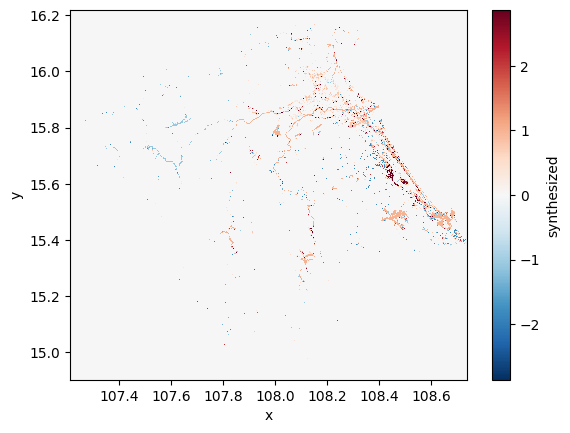

In [57]:
da_water.sel(time="2022-10-13T20:00:00").sel(site="ID4")

In [59]:
q_now = da_water.sel(time="2023-06-01T00:00:00")

for mode in eof_hydro.mode.values:
    site = eof_hydro["site"].sel(mode=mode).item()
    q_value = q_now.sel(site=site).item()
    training_q = eof_hydro["hydro_var"].sel(mode=mode)
    coefficients = eof_hydro["coefficients"].sel(mode=mode).values
    predicted_pc = np.polynomial.polynomial.polyval(q_value, coefficients)

    print(
        f"mode={mode}, site={site}, q={q_value:.3f}, "
        f"training range=[{training_q.min().item():.3f}, {training_q.max().item():.3f}], "
        f"predicted PC={predicted_pc:.3f}"
    )

print(
    f"raw reconstruction range=[{pred_image.min().item():.3f}, "
    f"{pred_image.max().item():.3f}]"
)

mode=1, site=ID2, q=2.370, training range=[3.640, 8.210], predicted PC=-320.442
mode=2, site=ID5, q=0.260, training range=[3.560, 6.080], predicted PC=-2856.438
mode=3, site=ID4, q=4.540, training range=[9.290, 11.480], predicted PC=-3703.953
raw reconstruction range=[-1.862, 2.862]
